# Multi-seed RL and bandit-algorithm comparison (MMLU and MixInstruct)

Feedback to address: (1) one seed per setting is not reliable, (2) epsilon-greedy is only one bandit algorithm.

One notebook, two datasets: set `DATASET` in the Config cell to `"mmlu"` or `"mixinstruct"` and run it once for each
(restart the kernel in between). Every cache and output file is prefixed with the dataset name, so the runs do not collide.

- **MMLU:** reuses the cached per-model correctness tables from `03_rl_vs_hybridllm_mmlu.ipynb`. Reward: +1 if the model's answer is correct, else -1.
- **MixInstruct:** reuses the cached outputs and BARTScores from `02_rl_vs_hybridllm_mixinstruct.ipynb` for the first 10,000
  training queries (4 of the 5 models) and for the 1,500 eval queries (all 5 models). Only `flan-t5-base` is missing on the
  training queries, and the notebook generates and scores it. Reward: +1 if BARTScore >= tau (the same tau as the earlier RL run), else -1.

The notebook runs two stages:

- **Stage A (cheap, many seeds):** several bandit algorithms on **frozen** question features (DeBERTa-v3-small mean-pooled
  embedding, PCA to 64 dims): epsilon-greedy and Boltzmann (softmax) with the same small MLP, epsilon-greedy with a linear
  model, LinUCB, and linear Thompson sampling. Pure numpy, CPU only, 20 seeds each.
- **Stage B (GPU, few seeds):** your actual fine-tuned RL (DeBERTa fine-tuned online), repeated over seeds, with two
  exploration rules on the same seeds: epsilon-greedy (the system in your slides) and Boltzmann/softmax exploration. This shows
  how much seed-to-seed variation the headline result has, and whether a different exploration rule changes it.

Both stages also report whether routing beats the **best single model** (chosen on validation), which is the baseline that matters
most. Results are saved to `ms_<dataset>_results.json`; run `final_comparison.ipynb` after both datasets are done.

**Protocol (fixes the selection issue from the last run):** the question pool is split into a training stream and a
**validation** set (`VAL_N` questions). Lambda (and any bandit hyperparameter) is chosen by validation utility. Results are
reported on the held-out test questions (1,531 for MMLU, 1,500 for MixInstruct), which are never used for selection or training. Reward during training is
`satisfaction (+1 / -1) - lambda * cost`; "utility" for judging is computed with a fixed `LAMBDA_EVAL`.

**Limits, stated up front:** Stage A uses frozen features, so it is a different (lighter) setting from the fine-tuned RL
and is a screening tool, not a replacement. Bandit hyperparameters are tried over a small grid only. HybridLLM and the
cascade were not re-run with multiple seeds here.

Run order: `DRY_RUN = True` first (a few minutes), then `False`. For MixInstruct the first real run also generates and scores
`flan-t5-base` on the 10,000 training queries (GPU, expected to take on the order of ten minutes; not timed).

## Step 0: preflight and setup

In [1]:
import sys, importlib, os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # must be set before torch is imported
REQUIRED = {"numpy": "numpy", "torch": "torch", "transformers": "transformers", "matplotlib": "matplotlib",
            "sentencepiece": "sentencepiece", "google.protobuf": "protobuf"}
missing = []
for mod, pip_name in REQUIRED.items():
    try: importlib.import_module(mod)
    except Exception: missing.append(pip_name)
if missing:
    raise RuntimeError("Missing packages: " + ", ".join(missing) +
        "\nInstall from a TERMINAL (pip inside Jupyter is blocked), then restart the kernel:\n  " +
        sys.executable + " -m pip install " + " ".join(missing))
print("preflight OK")

preflight OK


In [2]:
import os, gc, math, json, random, pickle, time, csv, shutil
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from collections import Counter
from transformers import (AutoTokenizer, AutoModel, AutoModelForSeq2SeqLM, AutoModelForCausalLM,
                          BartTokenizer, BartForConditionalGeneration)
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), "| free GB:", round(torch.cuda.mem_get_info()[0] / 1e9, 1))

WORK_DIR = os.path.expanduser("~/hybridllm_project")
CKPT_DIR = os.path.join(WORK_DIR, "ckpt_shared")
OUTPUT_DIR = os.path.join(WORK_DIR, "outputs")
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_ckpt(name, obj):
    tmp = f"{CKPT_DIR}/{name}.pkl.tmp"
    with open(tmp, "wb") as f: pickle.dump(obj, f)
    os.replace(tmp, f"{CKPT_DIR}/{name}.pkl")

def load_ckpt(name):
    path = f"{CKPT_DIR}/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f: return pickle.load(f)
    return None

def free_gpu():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def load_with_retry(model_class, model_id, **kwargs):
    try:
        return model_class.from_pretrained(model_id, **kwargs)
    except Exception as e:
        print(f"  [{model_id}] load failed ({type(e).__name__}); clearing cache and re-downloading...")
        cache_root = os.path.join(os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface")), "hub")
        target = os.path.join(cache_root, "models--" + model_id.replace("/", "--"))
        if os.path.exists(target): shutil.rmtree(target)
        return model_class.from_pretrained(model_id, force_download=True, **kwargs)

def save_csv(name, header, rows):
    with open(os.path.join(OUTPUT_DIR, f"{TAG}{name}.csv"), "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(header); w.writerows(rows)
print("helpers ready.")

Device: cuda
GPU: NVIDIA L40S | free GB: 47.2
helpers ready.


## Config

In [3]:
DRY_RUN = False           # True = tiny smoke test. Set False for the real run.
DATASET = "mixinstruct"          # "mmlu" or "mixinstruct": run the notebook once for each (restart the kernel in between)
assert DATASET in ("mmlu", "mixinstruct")
SRC_TAG = "mmlu_"         # (MMLU only) cached tables written by 03_rl_vs_hybridllm_mmlu.ipynb (read only)
TAG = ("dry_" if DRY_RUN else "") + f"ms_{DATASET}_"     # everything written here is prefixed with this
ROUTER_ID = "microsoft/deberta-v3-small"
MAX_PROMPT_LEN = {"mmlu": 512, "mixinstruct": 128}[DATASET]    # 128 matches the earlier MixInstruct RL run
QUALITY_LABEL = {"mmlu": "accuracy", "mixinstruct": "pass rate"}[DATASET]

LAMBDA_EVAL = 0.5         # fixed yardstick for utility, same for every method
VAL_N = {"mmlu": 1500, "mixinstruct": 1000}[DATASET]    # held out from the pool for choosing lambda / hyperparameters

# ---- MixInstruct only: generation settings for the one missing model (flan-t5-base) on the training queries
N_MIX = 10000             # the cached label-building queries: train_examples[:N_MIX]
MAX_NEW_TOKENS = 64       # same as the earlier MixInstruct runs
GEN_BS = {"flan-t5-small": 64, "flan-t5-base": 64, "flan-t5-large": 32, "flan-t5-xl": 16, "llama-2-7b-chat": 16}
EPS_START, EPS_END = 0.30, 0.05
TAU_START, TAU_END = 0.30, 0.03      # Boltzmann temperature schedule

# ---- Stage A (frozen features, numpy, many seeds)
N_SEEDS_A = 20
LAMBDAS_A = [0.1, 0.25, 0.5, 1.0, 2.0]
PCA_DIM = 64
MLP_HIDDEN, MLP_LR = 128, 1e-3
ALGOS = {   # name -> (family, settings). Two settings each for UCB / Thompson: the better one is picked on validation.
    "egreedy-mlp":    ("mlp", {"mode": "eps"}),
    "boltzmann-mlp":  ("mlp", {"mode": "boltz"}),
    "egreedy-linear": ("lin", {"mode": "eps", "param": None}),
    "linucb a=0.1":   ("lin", {"mode": "ucb", "param": 0.1}),
    "linucb a=0.5":   ("lin", {"mode": "ucb", "param": 0.5}),
    "linTS v=0.1":    ("lin", {"mode": "ts",  "param": 0.1}),
    "linTS v=0.5":    ("lin", {"mode": "ts",  "param": 0.5}),
}
REFERENCE_ALGO = "egreedy-mlp"

# ---- Stage B (fine-tuned epsilon-greedy RL, GPU, few seeds). ~12 min per run on your server.
RUN_STAGE_B = True
FT_ALGOS = ["eps", "boltz"]       # epsilon-greedy vs Boltzmann (softmax) exploration, both with the fine-tuned network
FT_LAMBDAS = {"mmlu": [0.25, 0.5], "mixinstruct": [0.5, 1.0]}[DATASET]
FT_SEEDS = [0, 1, 2]
FT_CHUNK = 2000           # checkpoint every this many steps

if DRY_RUN:
    N_SEEDS_A, LAMBDAS_A, VAL_N = 3, [0.25, 1.0], 100
    FT_LAMBDAS, FT_SEEDS, FT_CHUNK = [0.25], [0, 1], 200
    N_MIX = 500
print(f"DATASET={DATASET} | DRY_RUN={DRY_RUN} | Stage A: {len(ALGOS)} algos x {len(LAMBDAS_A)} lambdas x {N_SEEDS_A} seeds | "
      f"Stage B: {len(FT_ALGOS)} algos x {len(FT_LAMBDAS)} lambdas x {len(FT_SEEDS)} seeds (run={RUN_STAGE_B})")

DATASET=mixinstruct | DRY_RUN=False | Stage A: 7 algos x 5 lambdas x 20 seeds | Stage B: 2 algos x 2 lambdas x 3 seeds (run=True)


## Models, generation and scoring utilities

Needed only for MixInstruct, and only if a model's scores are not already cached (in practice `flan-t5-base` on the training
queries). Copied from `02_rl_vs_hybridllm_mixinstruct.ipynb`: greedy decoding, batched, resumable, BARTScore with
`facebook/bart-large-cnn`. The scorer is loaded lazily, so MMLU never touches it.

In [4]:
MODEL_IDS = [
    ("flan-t5-small",   "google/flan-t5-small",            False, 80e6),
    ("flan-t5-base",    "google/flan-t5-base",             False, 250e6),
    ("flan-t5-large",   "google/flan-t5-large",            False, 780e6),
    ("flan-t5-xl",      "google/flan-t5-xl",               False, 3e9),
    ("llama-2-7b-chat", "NousResearch/Llama-2-7b-chat-hf", True,  7e9),
]
MODEL_NAMES = [m[0] for m in MODEL_IDS]
PARAMS = np.array([m[3] for m in MODEL_IDS]); COSTS = PARAMS / PARAMS.max(); K = len(MODEL_NAMES)

def load_agent(name):
    _, model_id, is_causal, params = next(m for m in MODEL_IDS if m[0] == name)
    tok = AutoTokenizer.from_pretrained(model_id)
    if is_causal:
        tok.pad_token = tok.eos_token          # always reuse eos for padding (a shipped pad token can lie outside the embedding table)
        tok.padding_side = "left"
        model = load_with_retry(AutoModelForCausalLM, model_id, torch_dtype=torch.float16).to(DEVICE)
        assert tok.pad_token_id < model.get_input_embeddings().num_embeddings, "pad token id is outside the embedding table"
    else:
        model = load_with_retry(AutoModelForSeq2SeqLM, model_id, torch_dtype=torch.float16).to(DEVICE)
    model.eval()
    return {"name": name, "tok": tok, "model": model, "causal": is_causal}

def free_agent(entry):
    del entry["model"], entry["tok"]
    free_gpu()

OOV_REPLACED = {"n": 0}

@torch.no_grad()
def generate_batch(entry, queries):
    tok, model = entry["tok"], entry["model"]
    enc = tok(queries, return_tensors="pt", truncation=True, max_length=256, padding=True).to(DEVICE)
    if entry["causal"]:
        n_emb = model.get_input_embeddings().num_embeddings      # map any id without an embedding row to <unk> (avoids a CUDA assert)
        bad = enc["input_ids"] >= n_emb
        if bad.any():
            enc["input_ids"][bad] = tok.unk_token_id if tok.unk_token_id is not None else 0
            OOV_REPLACED["n"] += int(bad.sum())
    out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=tok.pad_token_id)
    if entry["causal"]:
        out = out[:, enc["input_ids"].shape[1]:]
    return tok.batch_decode(out, skip_special_tokens=True)

def run_generation(name, queries, cache_name):
    cache = load_ckpt(cache_name) or {}
    pending = [i for i in range(len(queries)) if i not in cache]
    if pending:
        entry = load_agent(name); bs = GEN_BS[name]
        pending.sort(key=lambda i: -len(queries[i]))
        t0 = time.time(); n_batches = math.ceil(len(pending) / bs)
        for bi in range(n_batches):
            idxs = pending[bi * bs:(bi + 1) * bs]
            for i, o in zip(idxs, generate_batch(entry, [queries[i] for i in idxs])):
                cache[i] = o
            if (bi + 1) % 20 == 0 or bi == n_batches - 1:
                save_ckpt(cache_name, cache)
                el = time.time() - t0
                print(f"  [{name}] {len(cache)}/{len(queries)} done | {el/60:.1f} min | est. remaining {el/(bi+1)*(n_batches-bi-1)/60:.1f} min")
        free_agent(entry)
    return [cache[i] for i in range(len(queries))]

class BARTScorer:
    def __init__(self, checkpoint="facebook/bart-large-cnn", device=DEVICE, max_length=1024):
        self.device, self.max_length = device, max_length
        self.tokenizer = BartTokenizer.from_pretrained(checkpoint)
        self.model = load_with_retry(BartForConditionalGeneration, checkpoint).to(device).eval()
        self.loss_fct = nn.NLLLoss(reduction="none", ignore_index=self.model.config.pad_token_id)
        self.lsm = nn.LogSoftmax(dim=1)
    @torch.no_grad()
    def score(self, srcs, tgts, batch_size=16):
        scores = []
        for i in range(0, len(srcs), batch_size):
            es = self.tokenizer(srcs[i:i+batch_size], max_length=self.max_length, truncation=True, padding=True, return_tensors="pt").to(self.device)
            et = self.tokenizer(tgts[i:i+batch_size], max_length=self.max_length, truncation=True, padding=True, return_tensors="pt").to(self.device)
            tgt_ids = et["input_ids"]
            out = self.model(input_ids=es["input_ids"], attention_mask=es["attention_mask"], labels=tgt_ids)
            logits = out.logits.view(-1, self.model.config.vocab_size)
            loss = self.loss_fct(self.lsm(logits), tgt_ids.view(-1)).view(tgt_ids.shape[0], -1)
            scores.extend((-(loss.sum(dim=1) / (tgt_ids != self.model.config.pad_token_id).sum(dim=1))).tolist())
        return scores

_bart = {"scorer": None}
def quality(hyps, refs):
    if _bart["scorer"] is None: _bart["scorer"] = BARTScorer()
    return _bart["scorer"].score(refs, hyps)

def score_cached(hyps, refs, cache_name):
    c = load_ckpt(cache_name)
    if c is None or len(c) != len(hyps):
        c = quality(hyps, refs); save_ckpt(cache_name, c)
    return np.array(c)
print("utilities ready.")

utilities ready.


## Load the quality tables

Both datasets end up as the same objects: `stream` / `val` / `test` (lists of dicts with a `prompt`), `Qs` / `Qv` / `Qt`
(1 if the model's answer is good enough, per question and model), and for MixInstruct also `Rs` / `Rv` / `Rt` (the raw BARTScores).
The last `VAL_N` queries of the pool become the validation set; the rest is the training stream. Nothing is re-scored except,
for MixInstruct, `flan-t5-base` on the training queries.

In [5]:
def build_mmlu():
    pool = load_ckpt(f"{SRC_TAG}pool_examples"); holdout = load_ckpt(f"{SRC_TAG}holdout_examples")
    assert pool is not None and holdout is not None, "run 03_rl_vs_hybridllm_mmlu.ipynb (DRY_RUN=False) first"
    if DRY_RUN: pool, holdout = pool[:500], holdout[:150]
    def load_table(split, n):
        C = np.zeros((n, K))
        for j, name in enumerate(MODEL_NAMES):
            cache = load_ckpt(f"{SRC_TAG}score_{split}_{name}")
            assert cache is not None and len(cache) >= n, f"missing cached scores: {SRC_TAG}score_{split}_{name}"
            for i in range(n): C[i, j] = cache[i][0]
        return C
    Qp, Qh = load_table("pool", len(pool)), load_table("holdout", len(holdout))
    return pool[:-VAL_N], pool[-VAL_N:], holdout, Qp[:-VAL_N], Qp[-VAL_N:], Qh, None, None, None

def build_mixinstruct():
    global TAU
    train_examples, _ = load_ckpt("examples")                      # same cached examples as the other notebooks
    eval_examples = load_ckpt("eval_examples")                     # the 1,500 held-out eval queries
    assert train_examples is not None and eval_examples is not None, "run 02_rl_vs_hybridllm_mixinstruct.ipynb (DRY_RUN=False) first"
    TAU = -4.5488                                                   # same satisfaction threshold as the earlier RL run
    rl_json = os.path.join(OUTPUT_DIR, "rl_results.json")
    if os.path.exists(rl_json):
        try: TAU = json.load(open(rl_json))["tau_satisfaction_threshold"]
        except Exception: pass
    ex = [{"prompt": e["query"], "query": e["query"], "reference": e["reference"]} for e in train_examples[:N_MIX]]
    ev = [{"prompt": e["query"], "query": e["query"], "reference": e["reference"]} for e in eval_examples[:(150 if DRY_RUN else len(eval_examples))]]
    queries, refs = [e["query"] for e in ex], [e["reference"] for e in ex]
    pre = "dry_" if DRY_RUN else ""
    Bp, Bt = np.zeros((len(ex), K)), np.zeros((len(ev), K))
    for j, name in enumerate(MODEL_NAMES):
        sc = load_ckpt(f"bart_hyb_{name}")                          # written by 02_rl_vs_hybridllm_mixinstruct.ipynb (real run)
        if sc is not None and len(sc) >= len(ex):
            Bp[:, j] = np.array(sc)[:len(ex)]
        else:
            print(f"  no cached training-query scores for {name}: generating and scoring {len(ex)} queries")
            Bp[:, j] = score_cached(run_generation(name, queries, f"{pre}gen_hyb_{name}"), refs, f"{pre}bart_hyb_{name}")
        te = load_ckpt(f"bart_eval_{name}")
        assert te is not None and len(te) >= len(ev), f"missing cached eval scores: bart_eval_{name}"
        Bt[:, j] = np.array(te)[:len(ev)]
    print(f"tau = {TAU:.4f}")
    return ex[:-VAL_N], ex[-VAL_N:], ev, (Bp >= TAU).astype(float)[:-VAL_N], (Bp >= TAU).astype(float)[-VAL_N:], \
           (Bt >= TAU).astype(float), Bp[:-VAL_N], Bp[-VAL_N:], Bt

stream, val, test, Qs, Qv, Qt, Rs, Rv, Rt = build_mmlu() if DATASET == "mmlu" else build_mixinstruct()
HAS_R = Rt is not None
print(f"{DATASET}: stream={len(stream)}  val={len(val)}  test={len(test)}")
print(f"{'model':>16} {'cost':>6} {QUALITY_LABEL + ' stream':>16} {QUALITY_LABEL + ' val':>14} {QUALITY_LABEL + ' test':>15}" + (f" {'BARTScore test':>15}" if HAS_R else ""))
for j, n in enumerate(MODEL_NAMES):
    print(f"{n:>16} {COSTS[j]:6.3f} {100*Qs[:, j].mean():15.1f}% {100*Qv[:, j].mean():13.1f}% {100*Qt[:, j].mean():14.1f}%"
          + (f" {Rt[:, j].mean():15.3f}" if HAS_R else ""))
if not DRY_RUN:
    print("\nsanity: test " + QUALITY_LABEL + " should match the earlier run: " +
          ("29.3 / 33.4 / 42.0 / 49.8 / 45.6 %" if DATASET == "mmlu" else "53.1 / 50.1 / 50.0 / 57.8 / 90.9 % (BARTScore -4.72 / -4.75 / -4.73 / -4.34 / -3.42)"))

def eval_choice(Q, ch, R=None):
    ch = np.asarray(ch); corr = Q[np.arange(len(Q)), ch]
    return {"acc": float(corr.mean()), "cost": float(COSTS[ch].mean()),
            "util": float((2 * corr - 1 - LAMBDA_EVAL * COSTS[ch]).mean()),
            "mq": float(R[np.arange(len(R)), ch].mean()) if R is not None else None,
            "shares": (np.bincount(ch, minlength=K) / len(ch)).tolist()}

tau = -4.5488
mixinstruct: stream=9000  val=1000  test=1500
           model   cost pass rate stream  pass rate val  pass rate test  BARTScore test
   flan-t5-small  0.011            55.4%          55.1%           53.1%          -4.720
    flan-t5-base  0.036            52.2%          54.7%           50.1%          -4.750
   flan-t5-large  0.111            53.1%          54.2%           50.0%          -4.727
      flan-t5-xl  0.429            61.8%          61.7%           57.8%          -4.344
 llama-2-7b-chat  1.000            92.1%          92.1%           90.9%          -3.424

sanity: test pass rate should match the earlier run: 53.1 / 50.1 / 50.0 / 57.8 / 90.9 % (BARTScore -4.72 / -4.75 / -4.73 / -4.34 / -3.42)


## Frozen question features (for Stage A)

DeBERTa-v3-small, **mean-pooled** token embeddings (mean pooling is more informative than the [CLS] token when the encoder is
not fine-tuned), then PCA to `PCA_DIM` dimensions fitted on the training stream only, whitened, plus a bias term.

In [6]:
def embed_prompts(prompts, bs=64):
    tok = AutoTokenizer.from_pretrained(ROUTER_ID)
    model = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE).eval()
    order = np.argsort([len(p) for p in prompts])[::-1]
    out = np.zeros((len(prompts), model.config.hidden_size), dtype=np.float32)
    with torch.no_grad():
        for b in range(0, len(order), bs):
            idx = order[b:b + bs]
            enc = tok([prompts[i] for i in idx], return_tensors="pt", truncation=True,
                      max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
            h = model(**enc).last_hidden_state
            m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
            out[idx] = ((h * m).sum(1) / m.sum(1)).float().cpu().numpy()
    del model; free_gpu()
    return out

def get_emb(name, examples):
    cached = load_ckpt(f"{TAG}emb_{name}")
    if cached is not None and len(cached) == len(examples): return cached
    e = embed_prompts([ex["prompt"] for ex in examples]); save_ckpt(f"{TAG}emb_{name}", e); return e

E_s, E_v, E_t = get_emb("stream", stream), get_emb("val", val), get_emb("test", test)
mu = E_s.mean(0)
_, S, Vt = np.linalg.svd(E_s - mu, full_matrices=False)
D = min(PCA_DIM, len(S)); Vd = Vt[:D].T; sd = S[:D] / np.sqrt(len(E_s) - 1)
def feats(E):
    Z = ((E - mu) @ Vd) / sd / np.sqrt(D)
    return np.hstack([Z, np.ones((len(E), 1))]).astype(np.float64)
Xs, Xv, Xt = feats(E_s), feats(E_v), feats(E_t)
print("feature shapes:", Xs.shape, Xv.shape, Xt.shape, "| mean row norm:", round(float(np.linalg.norm(Xs, axis=1).mean()), 2))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


feature shapes: (9000, 65) (1000, 65) (1500, 65) | mean row norm: 1.41


## Bandit algorithms (numpy)

All agents share one interface: `act` (pick a model for a question), `update` (learn from the observed reward for the
chosen model only), `values` (greedy value estimate for every model, used to evaluate the final policy).

- **epsilon-greedy MLP:** the same 128-ReLU head as the main RL (frozen features), epsilon 0.30 to 0.05.
- **Boltzmann MLP:** same head, but samples a model with probability proportional to `exp(value / tau)`, tau 0.30 to 0.03.
- **epsilon-greedy linear:** one ridge-regression reward model per model.
- **LinUCB** (Li et al., 2010): ridge model plus an uncertainty bonus `alpha * sqrt(x' A^-1 x)`.
- **Linear Thompson sampling** (Agrawal and Goyal, 2013): samples each model's weights from the posterior.

In [7]:
class MLPAgent:
    def __init__(self, d, rng, mode, hidden=MLP_HIDDEN, lr=MLP_LR):
        self.mode, self.lr, self.t = mode, lr, 0
        self.p = [rng.randn(d, hidden) * np.sqrt(2.0 / d), np.zeros(hidden), rng.randn(hidden, K) * 0.01, np.zeros(K)]
        self.m = [np.zeros_like(a) for a in self.p]; self.v = [np.zeros_like(a) for a in self.p]
    def _fwd(self, x):
        z = x @ self.p[0] + self.p[1]; h = np.maximum(z, 0.0); return z, h, h @ self.p[2] + self.p[3]
    def act(self, x, t, T, rng):
        q = self._fwd(x)[2]; frac = t / max(1, T - 1)
        if self.mode == "eps":
            eps = EPS_START + (EPS_END - EPS_START) * frac
            return int(rng.randint(K)) if rng.rand() < eps else int(np.argmax(q))
        tau = TAU_START + (TAU_END - TAU_START) * frac
        z = (q - q.max()) / tau; pr = np.exp(z); pr /= pr.sum()
        return int(rng.choice(K, p=pr))
    def update(self, x, a, r):
        z, h, q = self._fwd(x); dq = 2.0 * (q[a] - r)
        gW2 = np.zeros_like(self.p[2]); gW2[:, a] = h * dq
        gb2 = np.zeros(K); gb2[a] = dq
        dz = self.p[2][:, a] * dq * (z > 0)
        grads = [np.outer(x, dz), dz, gW2, gb2]
        self.t += 1; b1, b2 = 0.9, 0.999
        for i, g in enumerate(grads):
            self.m[i] = b1 * self.m[i] + (1 - b1) * g
            self.v[i] = b2 * self.v[i] + (1 - b2) * g * g
            mh = self.m[i] / (1 - b1 ** self.t); vh = self.v[i] / (1 - b2 ** self.t)
            self.p[i] -= self.lr * mh / (np.sqrt(vh) + 1e-8)
    def values(self, X):
        return np.maximum(X @ self.p[0] + self.p[1], 0.0) @ self.p[2] + self.p[3]

class LinearAgent:
    def __init__(self, d, rng, mode, param, ridge=1.0):
        self.mode, self.param = mode, param
        self.Ainv = np.stack([np.eye(d) / ridge for _ in range(K)]); self.b = np.zeros((K, d)); self.theta = np.zeros((K, d))
        self.jit = 1e-9 * np.eye(d)
    def act(self, x, t, T, rng):
        if self.mode == "ucb":
            bonus = self.param * np.sqrt(np.maximum((self.Ainv @ x) @ x, 0.0))
            return int(np.argmax(self.theta @ x + bonus))
        if self.mode == "ts":
            L = np.linalg.cholesky(self.Ainv + self.jit)
            th = self.theta + self.param * np.einsum("kij,kj->ki", L, rng.randn(K, x.shape[0]))
            return int(np.argmax(th @ x))
        eps = EPS_START + (EPS_END - EPS_START) * t / max(1, T - 1)
        return int(rng.randint(K)) if rng.rand() < eps else int(np.argmax(self.theta @ x))
    def update(self, x, a, r):
        Ax = self.Ainv[a] @ x
        self.Ainv[a] -= np.outer(Ax, Ax) / (1.0 + x @ Ax)
        self.Ainv[a] = 0.5 * (self.Ainv[a] + self.Ainv[a].T)
        self.b[a] += r * x; self.theta[a] = self.Ainv[a] @ self.b[a]
    def values(self, X):
        return X @ self.theta.T

def make_agent(family, settings, d, rng):
    if family == "mlp": return MLPAgent(d, rng, settings["mode"])
    return LinearAgent(d, rng, settings["mode"], settings["param"])

def run_agent(family, settings, lam, seed, X, Q):
    rng = np.random.RandomState(seed)
    order = rng.permutation(len(X))              # the first draw: same stream order for every algorithm at a given seed
    agent = make_agent(family, settings, X.shape[1], rng)
    T = len(order); correct = 0.0; raw_cost = 0.0
    for t, i in enumerate(order):
        a = agent.act(X[i], t, T, rng); c = Q[i, a]
        agent.update(X[i], a, (2 * c - 1) - lam * COSTS[a])
        correct += c; raw_cost += PARAMS[a]
    return agent, {"online_acc": correct / T, "online_raw_cost": raw_cost}

def eval_agent(agent):
    return {"val": eval_choice(Qv, np.argmax(agent.values(Xv), 1), Rv), "test": eval_choice(Qt, np.argmax(agent.values(Xt), 1), Rt)}
print("agents ready.")

agents ready.


## Stage A: run every (algorithm, lambda, seed)

Cached in one file and resumable. The same seed gives every algorithm the same stream order, so comparisons are paired.

In [8]:
res_name = f"{TAG}stageA_results"
resA = load_ckpt(res_name) or {}
jobs = [(a, lam, s) for a in ALGOS for lam in LAMBDAS_A for s in range(N_SEEDS_A)]
pending = [j for j in jobs if j not in resA]
print(f"{len(jobs)} runs total, {len(pending)} pending")
t0 = time.time()
for n, (a, lam, s) in enumerate(pending):
    fam, st = ALGOS[a]
    agent, stats = run_agent(fam, st, lam, s, Xs, Qs)
    resA[(a, lam, s)] = {**eval_agent(agent), **stats}
    if (n + 1) % 20 == 0 or n == len(pending) - 1:
        save_ckpt(res_name, resA)
        el = time.time() - t0
        print(f"  {n+1}/{len(pending)} | {el/60:.1f} min | est. remaining {(len(pending)-n-1)*el/(n+1)/60:.1f} min")
print("Stage A done.")

700 runs total, 700 pending
  20/700 | 0.3 min | est. remaining 11.7 min
  40/700 | 0.7 min | est. remaining 11.3 min
  60/700 | 1.0 min | est. remaining 10.9 min
  80/700 | 1.4 min | est. remaining 10.5 min
  100/700 | 1.7 min | est. remaining 10.2 min
  120/700 | 2.1 min | est. remaining 10.0 min
  140/700 | 2.5 min | est. remaining 9.8 min
  160/700 | 2.8 min | est. remaining 9.5 min
  180/700 | 3.2 min | est. remaining 9.3 min
  200/700 | 3.6 min | est. remaining 9.0 min
  220/700 | 3.7 min | est. remaining 8.0 min
  240/700 | 3.8 min | est. remaining 7.2 min
  260/700 | 3.8 min | est. remaining 6.5 min
  280/700 | 3.9 min | est. remaining 5.9 min
  300/700 | 4.0 min | est. remaining 5.3 min
  320/700 | 4.1 min | est. remaining 4.9 min
  340/700 | 4.2 min | est. remaining 4.5 min
  360/700 | 4.3 min | est. remaining 4.1 min
  380/700 | 4.4 min | est. remaining 3.7 min
  400/700 | 4.5 min | est. remaining 3.4 min
  420/700 | 4.6 min | est. remaining 3.1 min
  440/700 | 4.7 min | est

## Stage A results

For each algorithm, lambda is chosen by **mean validation utility across seeds**; the table reports the **test** results
(mean and standard deviation over seeds) at that lambda. For UCB and Thompson, the two parameter settings are separate rows,
so the better one is visible. "Paired diff" is the per-seed test-utility difference to `REFERENCE_ALGO`, with a bootstrap
95% interval over seeds.

In [9]:
def arr(a, lam, key, split="test"):
    return np.array([resA[(a, lam, s)][split][key] for s in range(N_SEEDS_A)])

def boot_ci(d, n=4000, seed=0):
    idx = np.random.RandomState(seed).randint(0, len(d), (n, len(d)))
    m = d[idx].mean(axis=1); return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

best_lam = {a: max(LAMBDAS_A, key=lambda l: arr(a, l, "util", "val").mean()) for a in ALGOS}
ref_u = arr(REFERENCE_ALGO, best_lam[REFERENCE_ALGO], "util")
fixed_val = [eval_choice(Qv, [j] * len(Qv), Rv) for j in range(K)]       # always-model-j baselines
fixed_test = [eval_choice(Qt, [j] * len(Qt), Rt) for j in range(K)]
best_fixed = int(np.argmax([e["util"] for e in fixed_val]))               # best single model, chosen on validation
rows, summaryA = [], {}
for a in ALGOS:
    l = best_lam[a]; acc, cost, ut = arr(a, l, "acc"), arr(a, l, "cost"), arr(a, l, "util")
    shl = np.array([resA[(a, l, s)]["test"]["shares"][K - 1] for s in range(N_SEEDS_A)])
    online_cost = np.array([resA[(a, l, s)]["online_raw_cost"] for s in range(N_SEEDS_A)]) / 1e12
    d, lo, hi = boot_ci(ut - ref_u) if a != REFERENCE_ALGO else (0.0, 0.0, 0.0)
    summaryA[a] = {"lambda": l, "acc": [acc.mean(), acc.std(ddof=1)], "cost": [cost.mean(), cost.std(ddof=1)],
                   "util": [ut.mean(), ut.std(ddof=1)], "paired_diff": [d, lo, hi],
                   "diff_vs_best_fixed": list(boot_ci(ut - fixed_test[best_fixed]["util"]))}
    mq = arr(a, l, "mq") if HAS_R else None
    row = [a, l, f"{100*acc.mean():.1f} +- {100*acc.std(ddof=1):.1f}"]
    if HAS_R: row.append(f"{mq.mean():.3f} +- {mq.std(ddof=1):.3f}")
    row += [f"{cost.mean():.3f} +- {cost.std(ddof=1):.3f}", f"{ut.mean():+.3f} +- {ut.std(ddof=1):.3f}", f"{100*shl.mean():.1f}%",
            f"{online_cost.mean():.1f}T", "-" if a == REFERENCE_ALGO else f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]"]
    rows.append(row)
hdr = ["algorithm", "lambda*", f"test {QUALITY_LABEL} % (mean+-sd)"] + (["test BARTScore"] if HAS_R else []) + \
      ["test cost", "test utility", "to Llama", "learning cost", f"paired diff vs {REFERENCE_ALGO}"]
print(f"{N_SEEDS_A} seeds. lambda chosen on validation; metrics on the test set.\n")
print(" | ".join(f"{h:>22}" if i else f"{h:>16}" for i, h in enumerate(hdr)))
for r in rows: print(" | ".join(f"{str(x):>22}" if i else f"{str(x):>16}" for i, x in enumerate(r)))
save_csv("stageA_summary", hdr, rows)

print("\nFixed-model references on the test set:")
for j, n in enumerate(MODEL_NAMES):
    e = fixed_test[j]; print(f"  always {n:>16}: cost {e['cost']:.3f}  {QUALITY_LABEL} {100*e['acc']:.1f}%  utility {e['util']:+.3f}" + ("   <- best single model on validation" if j == best_fixed else ""))
print(f"\nDoes routing beat the best single model ({MODEL_NAMES[best_fixed]}, test utility {fixed_test[best_fixed]['util']:+.3f})?")
print("difference in test utility, bandit minus that model (mean over seeds, 95% bootstrap interval over seeds):")
for a in ALGOS:
    d, lo, hi = summaryA[a]["diff_vs_best_fixed"]
    print(f"  {a:>16} (lambda={best_lam[a]}): {d:+.3f} [{lo:+.3f}, {hi:+.3f}]  " + ("better" if lo > 0 else ("worse" if hi < 0 else "not distinguishable")))

print("\nFull grid (test utility, mean over seeds), rows = algorithm, columns = training lambda:")
print(f"{'':>16} " + " ".join(f"{l:>8}" for l in LAMBDAS_A))
for a in ALGOS: print(f"{a:>16} " + " ".join(f"{arr(a, l, 'util').mean():+8.3f}" for l in LAMBDAS_A))

20 seeds. lambda chosen on validation; metrics on the test set.

       algorithm |                lambda* | test pass rate % (mean+-sd) |         test BARTScore |              test cost |           test utility |               to Llama |          learning cost | paired diff vs egreedy-mlp
     egreedy-mlp |                    0.5 |            86.4 +- 1.7 |        -3.393 +- 0.048 |         0.597 +- 0.066 |        +0.428 +- 0.010 |                  56.9% |                  39.5T |                      -
   boltzmann-mlp |                    0.5 |            86.5 +- 1.8 |        -3.377 +- 0.058 |         0.597 +- 0.069 |        +0.431 +- 0.012 |                  54.9% |                  34.9T | +0.002 [-0.004, +0.009]
  egreedy-linear |                    0.5 |            86.3 +- 0.7 |        -3.365 +- 0.028 |         0.575 +- 0.014 |        +0.438 +- 0.017 |                  52.2% |                  32.9T | +0.010 [+0.001, +0.019]
    linucb a=0.1 |                    0.5 |            8

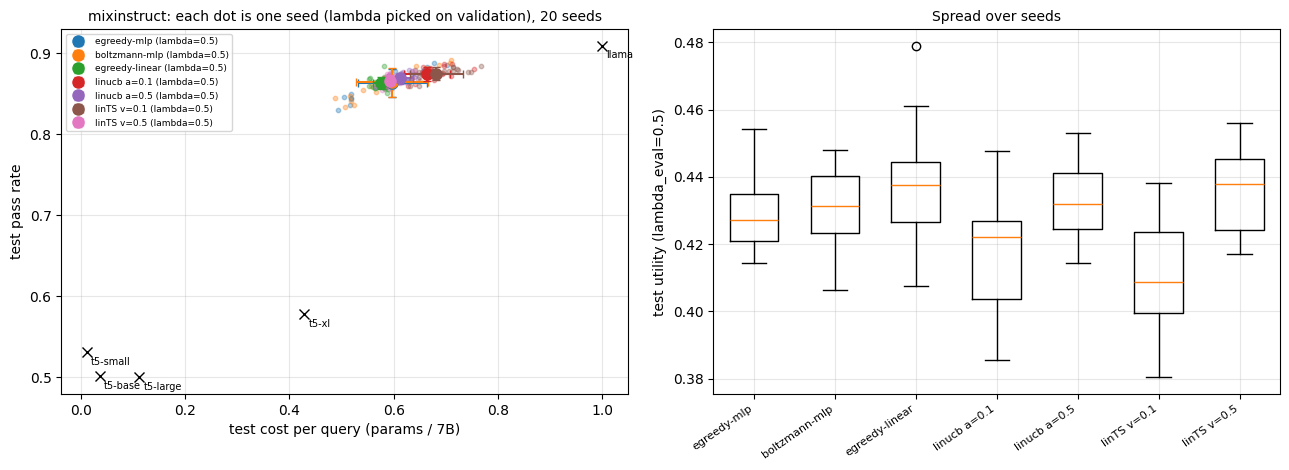

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
colors = plt.cm.tab10(np.arange(len(ALGOS)))
for (a, c) in zip(ALGOS, colors):
    l = best_lam[a]
    ax[0].scatter(arr(a, l, "cost"), arr(a, l, "acc"), s=10, color=c, alpha=0.35)
    ax[0].errorbar(arr(a, l, "cost").mean(), arr(a, l, "acc").mean(), xerr=arr(a, l, "cost").std(ddof=1),
                   yerr=arr(a, l, "acc").std(ddof=1), fmt="o", ms=8, color=c, capsize=3, label=f"{a} (lambda={l})")
    ax[1].boxplot([arr(a, l, "util")], positions=[list(ALGOS).index(a)], widths=0.6, showfliers=True)
for j, n in enumerate(MODEL_NAMES):
    e = eval_choice(Qt, [j] * len(Qt)); ax[0].plot(e["cost"], e["acc"], "kx", ms=7)
    ax[0].annotate(n.replace("flan-t5-", "t5-").replace("llama-2-7b-chat", "llama"), (e["cost"], e["acc"]), textcoords="offset points", xytext=(3, -9), fontsize=7)
ax[0].set_xlabel("test cost per query (params / 7B)"); ax[0].set_ylabel(f"test {QUALITY_LABEL}"); ax[0].grid(alpha=0.3)
ax[0].set_title(f"{DATASET}: each dot is one seed (lambda picked on validation), {N_SEEDS_A} seeds", fontsize=10); ax[0].legend(fontsize=6.5)
ax[1].set_xticks(range(len(ALGOS))); ax[1].set_xticklabels(list(ALGOS), rotation=35, ha="right", fontsize=8)
ax[1].set_ylabel(f"test utility (lambda_eval={LAMBDA_EVAL})"); ax[1].grid(alpha=0.3); ax[1].set_title("Spread over seeds", fontsize=10)
plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, f"{TAG}stageA.png"), dpi=150); plt.show()

## Stage B: the fine-tuned RL, epsilon-greedy and Boltzmann, repeated over seeds

Same architecture and training as the main RL (DeBERTa-v3-small fine-tuned online, 128-ReLU head, batch size 1, AdamW lr 2e-5),
except that it trains on the stream **without the validation questions**, and the stream order, head initialisation and
exploration all depend on the seed. Two exploration rules are compared on the same seeds (so differences are paired):

- `eps`: epsilon-greedy, epsilon 0.30 to 0.05 (the system in the slides).
- `boltz`: Boltzmann/softmax exploration, sampling a model with probability proportional to `exp(value / tau)`, tau 0.30 to 0.03.

Each run is cached and checkpointed every `FT_CHUNK` steps. On your server a run took about 12 minutes on MMLU; MixInstruct
sequences are shorter, so it should be faster (not timed). Reduce `FT_ALGOS` / `FT_LAMBDAS` / `FT_SEEDS` if time is short.

In [11]:
class OrchestratorHead(nn.Module):
    def __init__(self, hidden_size, n_agents):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(hidden_size, 128), nn.ReLU(), nn.Linear(128, n_agents))
    def forward(self, state): return self.net(state)

ft_tok = AutoTokenizer.from_pretrained(ROUTER_ID)
stream_prompts, val_prompts, test_prompts = [e["prompt"] for e in stream], [e["prompt"] for e in val], [e["prompt"] for e in test]

@torch.no_grad()
def ft_values(backbone, head, prompts, bs=32):
    out = []
    for b in range(0, len(prompts), bs):
        enc = ft_tok(prompts[b:b + bs], return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
        out.append(head(backbone(**enc).last_hidden_state[:, 0]).cpu().numpy())
    return np.concatenate(out)

def train_ft(algo, lam, seed):
    name = f"{TAG}ft_{algo}_lam{lam}_seed{seed}"
    done = load_ckpt(name + "_result")
    if done is not None: return done
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    order = rng.permutation(len(stream)); T = len(order)
    backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)
    head = OrchestratorHead(backbone.config.hidden_size, K).to(DEVICE)
    opt = torch.optim.AdamW(list(backbone.parameters()) + list(head.parameters()), lr=2e-5)
    start, correct, raw_cost = 0, 0.0, 0.0
    st = load_ckpt(name + "_state")
    if st is not None:
        backbone.load_state_dict(st["b"]); head.load_state_dict(st["h"]); opt.load_state_dict(st["o"])
        rng.set_state(st["rng"]); start, correct, raw_cost = st["step"], st["correct"], st["raw_cost"]
        print(f"  [{algo} lam={lam} seed={seed}] resumed from step {start}")
    t0 = time.time()
    for t in range(start, T):
        i = order[t]; frac = t / max(1, T - 1)
        enc = ft_tok(stream_prompts[i], return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN).to(DEVICE)
        values = head(backbone(**enc).last_hidden_state[:, 0]).squeeze(0)
        if algo == "eps":
            eps = EPS_START + (EPS_END - EPS_START) * frac
            a = int(rng.randint(K)) if rng.rand() < eps else int(torch.argmax(values).item())
        else:                                          # "boltz"
            tau = TAU_START + (TAU_END - TAU_START) * frac
            v = values.detach().cpu().numpy().astype(np.float64)
            pr = np.exp((v - v.max()) / tau); pr /= pr.sum()
            a = int(rng.choice(K, p=pr))
        c = Qs[i, a]; reward = (2 * c - 1) - lam * COSTS[a]
        loss = F.mse_loss(values[a], torch.tensor(reward, dtype=torch.float32, device=DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
        correct += c; raw_cost += PARAMS[a]
        if (t + 1) % FT_CHUNK == 0 and t + 1 < T:
            save_ckpt(name + "_state", {"b": backbone.state_dict(), "h": head.state_dict(), "o": opt.state_dict(),
                                        "rng": rng.get_state(), "step": t + 1, "correct": correct, "raw_cost": raw_cost})
            print(f"  [{algo} lam={lam} seed={seed}] step {t+1}/{T} | {(time.time()-t0)/60:.1f} min")
    backbone.eval(); head.eval()
    result = {"val": eval_choice(Qv, np.argmax(ft_values(backbone, head, val_prompts), 1), Rv),
              "test": eval_choice(Qt, np.argmax(ft_values(backbone, head, test_prompts), 1), Rt),
              "online_acc": correct / T, "online_raw_cost": raw_cost}
    sp = f"{CKPT_DIR}/{name}_state.pkl"
    if os.path.exists(sp): os.remove(sp)
    del backbone, head, opt; free_gpu()
    return result

resB = {}
if RUN_STAGE_B:
    for algo in FT_ALGOS:
        for lam in FT_LAMBDAS:
            for seed in FT_SEEDS:
                t0 = time.time(); resB[(algo, lam, seed)] = train_ft(algo, lam, seed)
                r = resB[(algo, lam, seed)]["test"]
                print(f"{algo} lam={lam} seed={seed}: test {QUALITY_LABEL} {100*r['acc']:.1f}%  cost {r['cost']:.3f}  utility {r['util']:+.3f}  ({(time.time()-t0)/60:.1f} min)")
else:
    print("RUN_STAGE_B = False: skipped.")

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [eps lam=0.5 seed=0] step 2000/9000 | 1.3 min
  [eps lam=0.5 seed=0] step 4000/9000 | 2.6 min
  [eps lam=0.5 seed=0] step 6000/9000 | 3.9 min
  [eps lam=0.5 seed=0] step 8000/9000 | 5.2 min
eps lam=0.5 seed=0: test pass rate 87.1%  cost 0.682  utility +0.401  (5.8 min)


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [boltz lam=1.0 seed=1] step 2000/9000 | 1.4 min
  [boltz lam=1.0 seed=1] step 4000/9000 | 2.8 min
  [boltz lam=1.0 seed=1] step 6000/9000 | 4.2 min
  [boltz lam=1.0 seed=1] step 8000/9000 | 5.6 min
boltz lam=1.0 seed=1: test pass rate 76.8%  cost 0.322  utility +0.375  (6.2 min)


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [boltz lam=1.0 seed=2] step 2000/9000 | 1.3 min
  [boltz lam=1.0 seed=2] step 4000/9000 | 2.7 min
  [boltz lam=1.0 seed=2] step 6000/9000 | 4.1 min
  [boltz lam=1.0 seed=2] step 8000/9000 | 5.5 min
boltz lam=1.0 seed=2: test pass rate 86.1%  cost 0.500  utility +0.471  (6.2 min)


Fine-tuned RL, 3 seeds (mean +- sd over seeds; test set). * = lambda chosen on validation for that algorithm

           algorithm |               lambda |          val utility |     test pass rate % |            test cost |         test utility |             to Llama | per-seed test utility
                 eps |                  0.5 |               +0.432 |          88.2 +- 2.0 |       0.723 +- 0.163 |      +0.403 +- 0.045 |                68.2% | +0.401 +0.359 +0.450
                 eps |                 1.0* |               +0.448 |          82.1 +- 3.1 |       0.438 +- 0.069 |      +0.422 +- 0.029 |                41.5% | +0.439 +0.439 +0.388
               boltz |                 0.5* |               +0.483 |          89.2 +- 0.7 |       0.643 +- 0.013 |      +0.464 +- 0.008 |                62.0% | +0.468 +0.468 +0.455
               boltz |                  1.0 |               +0.453 |          81.9 +- 4.7 |       0.422 +- 0.091 |      +0.426 +- 0.048 |                40.6% | 

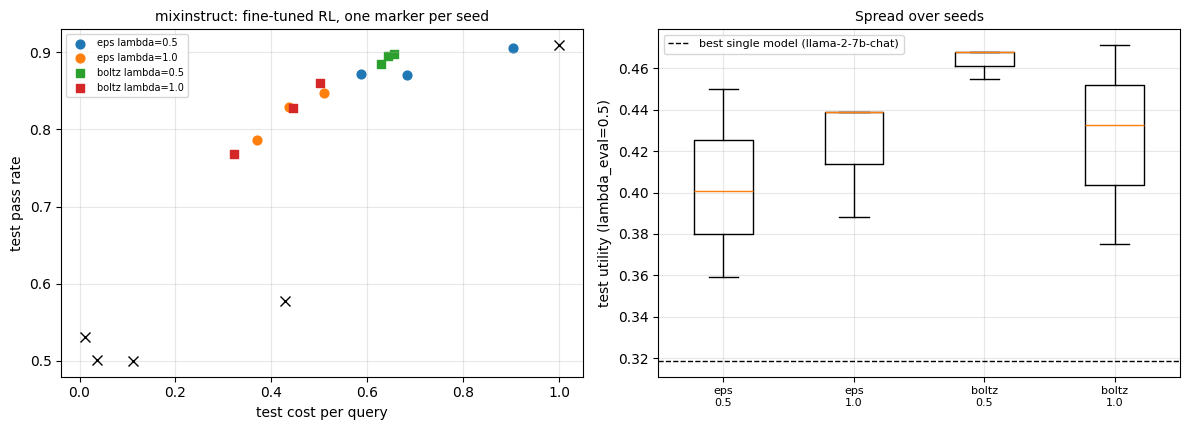

In [12]:
summaryB, selectedB = {}, {}
if RUN_STAGE_B and resB:
    sd = lambda x: float(x.std(ddof=1)) if len(x) > 1 else 0.0
    for algo in FT_ALGOS:
        for lam in FT_LAMBDAS:
            rs = [resB[(algo, lam, s)] for s in FT_SEEDS]
            summaryB[(algo, lam)] = {
                "val_util": float(np.mean([r["val"]["util"] for r in rs])),
                "acc": [r["test"]["acc"] for r in rs], "cost": [r["test"]["cost"] for r in rs],
                "util": [r["test"]["util"] for r in rs], "to_llama": [r["test"]["shares"][K - 1] for r in rs],
                "mq": [r["test"]["mq"] for r in rs] if HAS_R else None}
        selectedB[algo] = max(FT_LAMBDAS, key=lambda l: summaryB[(algo, l)]["val_util"])      # lambda chosen on validation
    print(f"Fine-tuned RL, {len(FT_SEEDS)} seeds (mean +- sd over seeds; test set). * = lambda chosen on validation for that algorithm\n")
    hdrB = ["algorithm", "lambda", "val utility", f"test {QUALITY_LABEL} %", "test cost", "test utility", "to Llama", "per-seed test utility"]
    rowsB = []
    for algo in FT_ALGOS:
        for lam in FT_LAMBDAS:
            m = summaryB[(algo, lam)]
            rowsB.append([algo, f"{lam}" + ("*" if selectedB[algo] == lam else ""), f"{m['val_util']:+.3f}",
                          f"{100*np.mean(m['acc']):.1f} +- {100*sd(np.array(m['acc'])):.1f}",
                          f"{np.mean(m['cost']):.3f} +- {sd(np.array(m['cost'])):.3f}",
                          f"{np.mean(m['util']):+.3f} +- {sd(np.array(m['util'])):.3f}", f"{100*np.mean(m['to_llama']):.1f}%",
                          " ".join(f"{u:+.3f}" for u in m["util"])])
    for r in [hdrB] + rowsB: print(" | ".join(f"{str(x):>20}" for x in r))
    save_csv("stageB_summary", hdrB, rowsB)

    print(f"\nBest single model on validation: {MODEL_NAMES[best_fixed]} (test utility {fixed_test[best_fixed]['util']:+.3f}). Fine-tuned RL minus that model, per seed:")
    for algo in FT_ALGOS:
        d = np.array(summaryB[(algo, selectedB[algo])]["util"]) - fixed_test[best_fixed]["util"]
        print(f"  {algo:>6} (lambda={selectedB[algo]}): " + " ".join(f"{x:+.3f}" for x in d) + f"   mean {d.mean():+.3f}")
    if len(FT_ALGOS) == 2:
        a1, a2 = FT_ALGOS
        d = np.array(summaryB[(a2, selectedB[a2])]["util"]) - np.array(summaryB[(a1, selectedB[a1])]["util"])
        print(f"\nPaired per-seed difference in test utility, {a2} minus {a1} (each at its own chosen lambda): "
              + " ".join(f"{x:+.3f}" for x in d) + f"   mean {d.mean():+.3f}  (only {len(d)} seeds: treat as indicative)")
    print("\nfor comparison, the frozen-feature versions at the same lambdas (test utility, mean over Stage A seeds):")
    for algo, fa in (("eps", "egreedy-mlp"), ("boltz", "boltzmann-mlp")):
        if algo in FT_ALGOS and fa in ALGOS:
            print("  " + fa + ": " + "  ".join(f"lambda={l}: {arr(fa, l, 'util').mean():+.3f}" for l in FT_LAMBDAS if l in LAMBDAS_A))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.4)); mk = {"eps": "o", "boltz": "s"}
    for algo in FT_ALGOS:
        for lam in FT_LAMBDAS:
            m = summaryB[(algo, lam)]; ax[0].scatter(m["cost"], m["acc"], marker=mk.get(algo, "o"), s=40, label=f"{algo} lambda={lam}")
    for j, n in enumerate(MODEL_NAMES):
        ax[0].plot(fixed_test[j]["cost"], fixed_test[j]["acc"], "kx", ms=7)
    ax[0].set_xlabel("test cost per query"); ax[0].set_ylabel(f"test {QUALITY_LABEL}"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=7)
    ax[0].set_title(f"{DATASET}: fine-tuned RL, one marker per seed", fontsize=10)
    keys = [(a, l) for a in FT_ALGOS for l in FT_LAMBDAS]
    ax[1].boxplot([summaryB[k]["util"] for k in keys]); ax[1].axhline(fixed_test[best_fixed]["util"], color="k", ls="--", lw=1, label=f"best single model ({MODEL_NAMES[best_fixed]})")
    ax[1].set_xticks(range(1, len(keys) + 1)); ax[1].set_xticklabels([f"{a}\n{l}" for a, l in keys], fontsize=8)
    ax[1].set_ylabel(f"test utility (lambda_eval={LAMBDA_EVAL})"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8); ax[1].set_title("Spread over seeds", fontsize=10)
    plt.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, f"{TAG}stageB.png"), dpi=150); plt.show()

## Save everything the final-comparison notebook needs

In [13]:
tl = lambda x: [float(v) for v in x]
stageA_json = {}
for a in ALGOS:
    l = best_lam[a]
    stageA_json[a] = {"lambda": l, "val_util": float(arr(a, l, "util", "val").mean()),
                      "test_acc": tl(arr(a, l, "acc")), "test_cost": tl(arr(a, l, "cost")), "test_util": tl(arr(a, l, "util")),
                      "test_mq": tl(arr(a, l, "mq")) if HAS_R else None,
                      "to_llama": [float(resA[(a, l, s)]["test"]["shares"][K - 1]) for s in range(N_SEEDS_A)],
                      "paired_diff_vs_reference": summaryA[a]["paired_diff"], "diff_vs_best_fixed": summaryA[a]["diff_vs_best_fixed"]}
out = {"dataset": DATASET, "dry_run": DRY_RUN, "quality_label": QUALITY_LABEL, "has_bartscore": HAS_R,
       "tau": float(TAU) if DATASET == "mixinstruct" else None, "lambda_eval": LAMBDA_EVAL, "val_n": VAL_N,
       "n_stream": len(stream), "n_test": len(test), "n_seeds_stage_a": N_SEEDS_A, "lambdas_stage_a": LAMBDAS_A,
       "reference_algo": REFERENCE_ALGO, "model_names": MODEL_NAMES, "costs": tl(COSTS), "best_fixed": MODEL_NAMES[best_fixed],
       "fixed_val": {n: fixed_val[j] for j, n in enumerate(MODEL_NAMES)}, "fixed_test": {n: fixed_test[j] for j, n in enumerate(MODEL_NAMES)},
       "stage_a": stageA_json,
       "stage_b": {f"{a}|{l}": v for (a, l), v in summaryB.items()}, "stage_b_selected_lambda": selectedB,
       "ft_algos": FT_ALGOS, "ft_seeds": FT_SEEDS}
with open(os.path.join(OUTPUT_DIR, f"{TAG}results.json"), "w") as f: json.dump(out, f, indent=2, default=float)
print("saved", os.path.join(OUTPUT_DIR, f"{TAG}results.json"))

saved /home/bhavana.ravi/hybridllm_project/outputs/ms_mixinstruct_results.json
